## 오늘 할 일

- **Recap**: 부분회귀 (Practice 7) 다시 보기
- **Practice 1**: Niño3.4 지수는 몇 달 전의 자기 자신과 얼마나 닮았을까?
- **Practice 2**: 전주 월강수는 어떨까?

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
from scipy.stats import linregress
from statsmodels.tsa.stattools import acf   # 자기상관계수 (+ 신뢰구간) 계산
from scipy.signal import detrend            # 선형 추세 제거

## Recap: Partial regression

수업 슬라이드의 A, B, C를 Practice 7에 대응시키면

- A (predictand): SLP
- B (predictor): ENSO
- C (predictor): 전주 강수

알고 싶은 것은 **ENSO와 관련된 변동을 제외한 뒤, 전주 강수(C)와 SLP(A)가 얼마나 함께 변하는가**이다.

B와 C로 A를 함께 설명하는 **다중회귀식**은 다음과 같다.

$$
A^* = a\,B + b\,C + c
$$

- $A^*$: B와 C로 추정한 A
- $b$: B를 고정했을 때 C가 1 증가하면 A가 평균적으로 변하는 양

**부분회귀(partial regression)**로도 같은 $b$를 구할 수 있다.

ENSO(B)는 SLP(A)와 전주 강수(C) 모두와 관련되어 있다. 따라서 A를 C에 그냥 회귀하면 **ENSO와 관련된 변동까지 섞여서** 나타날 수 있다.

이를 구분하기 위해 **A와 C 각각에서 B로 설명되는 부분을 제거하고, 남은 값끼리 회귀**한다.

$$
(A - a_{B,A}\, B) = b\,(C - a_{B,C}\, B) + \varepsilon
$$

- $a_{B,A}$: B에 대한 A의 회귀계수
- $a_{B,C}$: B에 대한 C의 회귀계수
- $b$: 부분회귀계수 — B의 선형적 영향을 제외한 뒤의 C와 A 사이의 관계

위 식은 평균이 제거된 자료를 가정해 절편을 생략한 표현이다. 부분회귀는 **통계적 관계**를 나타내며, 그 자체로 인과관계를 증명하지는 않는다.

답($b=0.3$)을 미리 정해 둔 가짜 자료로 확인해 보자. 무작위 잡음이 있으므로 계산값은 정확히 0.3이 아닐 수 있다.

In [2]:
#----- 답을 알고 있는 가짜 자료 -----
rng = np.random.default_rng(0)
N = 1000

B = rng.standard_normal(N)                     # ENSO
C = 0.8*B + 0.6*rng.standard_normal(N)         # 전주 강수 : B 의 영향을 받는다 (B -> C)
A = 0.5*B + 0.3*C + rng.standard_normal(N)     # SLP : B 와 C 둘 다의 영향을 받는다 (B -> A, C -> A)

In [3]:
#----- 1. 그냥 회귀 (Practice 7 의 Practice 1) -----
print(linregress(C, A)[0])         # 약 0.65 : B 를 거친 관계까지 섞여서 0.3 보다 크다

0.6468861994211085


In [4]:
#----- 2. 부분회귀 (Practice 7 의 Practice 2) -----
Cn = C - linregress(B, C)[0]*B     # Practice 7 : prn   = pr   - regnp*ninos
An = A - linregress(B, A)[0]*B     # Practice 7 : anomn = anom - regnsninos  (격자마다 같은 계산)

print(linregress(Cn, An)[0])       # 약 0.3 : C -> A 관계만 남는다

0.31225046481167795


In [5]:
# 참고: 다중회귀 A* = a*B + b*C + c 를 한 번에 풀어도, C 의 계수 b 는 부분회귀계수와 같다
X = np.column_stack([B, C, np.ones(N)])
a, b, c = np.linalg.lstsq(X, A, rcond=None)[0]
print(a, b, c)

0.4373293028403765 0.3122504648116778 -0.048342451830958935


## Autocorrelation

**자기상관(autocorrelation)**: 하나의 시계열에서 일정한 시간 간격(lag)을 두고 떨어진 값들이 얼마나 비슷하게 변하는지 나타내는 상관계수

예를 들어 월별 자료에서

- lag = 1개월: 이번 달과 다음 달 값의 관계
- lag = 3개월: 이번 달과 3개월 뒤 값의 관계
- lag = 12개월: 이번 달과 1년 뒤 값의 관계

$$
R_{auto}(\tau) = \frac{\overline{x'(t)\,x'(t+\tau)}}{\sigma^2}
$$

- $\tau$: 시간 간격(lag)
- $x'$: 평균을 제거한 값
- $R_{auto}(0)=1$: 같은 시점의 값끼리 비교하므로 1

lag를 0, 1, 2, ...로 바꾸어 가며 자기상관계수를 그린 그림을 **correlogram**이라고 한다.

*참고:* 위 식은 개념을 나타낸 것이며, 실제 유한한 자료에서 ACF를 추정하는 방법은 여러 가지가 있다. 아래에서는 `acf` 함수로 계산한다.

## Practice 1 Correlogram for ENSO index

### 1. Make monthly ENSO index

Niño3.4 영역의 평균 SST에서 **각 달의 평년값(climatology)**을 빼서 anomaly를 계산한다. 이렇게 하면 계절에 따른 평균적인 SST 변화를 제거하고, 평년보다 따뜻하거나 차가운 변동을 살펴볼 수 있다.

In [6]:
##################### Plot Correlogram for Nino index ########################
#------------ Reading .nc data -------------
dset = xr.open_dataset('../data/sst.mnmean.nc')
sst = dset['sst']

#------------ Calculate Nino index ---------
nino34 = sst.where((sst.lat<5) & (sst.lat>-5) & (sst.lon>190) & (sst.lon<240), drop=True).mean(dim=['lat','lon'])

#---------- Calculate climatology ----------
clim = nino34.sel(time=slice('1982-01','2022-12')).groupby('time.month').mean(dim='time')

#---------- Calculate anomalies ------------
nino = (nino34.groupby('time.month') - clim)
print(nino.shape)                # (time,) : 매달 1개 값

(494,)


### 2. Conduct autocorrelation analysis & plot

**새로 쓰는 함수**

- `acf(x, alpha=0.05, nlags=N)`: 시계열 `x`의 lag 0 ~ N 자기상관계수를 계산한다. `alpha=0.05`를 주면 95% 신뢰구간도 함께 반환한다.
- `detrend(x, type='linear')`: 시계열 x에 회귀직선을 적합하여 선형적인 증가 또는 감소 추세를 구하고, 이를 원래 자료에서 제거하는 함수

[1.         0.95354736 0.86957754 0.76317322]


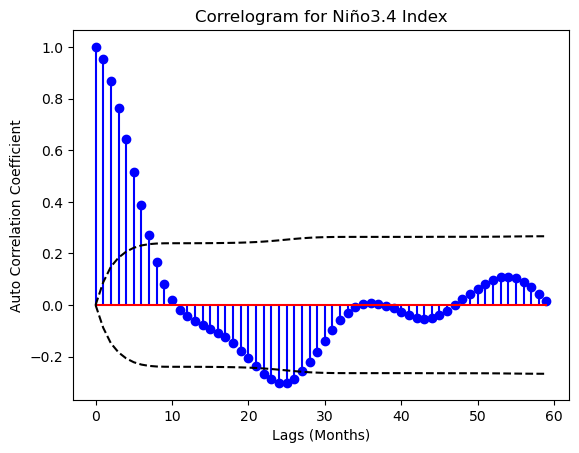

In [7]:
#---------- Remove linear trend ------------
#nino  =  detrend(nino, type='linear')      # linear detrending
# 장기 추세가 남아 있으면 자기상관에도 영향을 줄 수 있다.
#----- Calculate autocorrelation and confidence intervals ---
# acf(시계열, alpha=0.05 : 95% 신뢰구간도 계산, nlags : 몇 lag 까지)
acf_total, conf  =  acf(nino, alpha=0.05, nlags=len(nino))
print(acf_total[0:4])            # lag 0, 1, 2, 3 의 자기상관계수 (lag 0 은 항상 1)

# conf 는 [acf - 신뢰구간, acf + 신뢰구간] 이다
# 각 줄의 평균(= acf 값)을 빼면, 0 을 중심으로 한 신뢰구간만 남는다
conf -= conf.mean(axis=1)[:,None]  # (same as conf = conf - conf.mean(axis=1)[:,None])

# ------------- Plot Correlogram --------------
plt.stem(np.arange(0,60,1), acf_total[0:60], linefmt='b-', markerfmt='bo', basefmt='r-')   # 파란 점 : lag 별 자기상관계수
# 점선 (95% 신뢰구간) : 진짜 상관이 0 이어도 우연히 나올 수 있는 범위
#   -> 막대가 점선 밖으로 나가면 유의하다

plt.plot(np.arange(0,60,1), conf[0:60], 'k--')
plt.title('Correlogram for Niño3.4 Index')
plt.xlabel('Lags (Months)')
plt.ylabel('Auto Correlation Coefficient')
plt.show()


In [8]:
# 확인: lag 1 자기상관계수를 직접 계산해서 acf 결과와 비교한다
x = nino.values - nino.values.mean()     # x' : 평균을 뺀 값

r1 = (x[:-1]*x[1:]).sum() / (x*x).sum()  # x'(t) 와 x'(t+1) 을 곱해서 더하고, x' 제곱합으로 나눈다
print(round(r1, 4), round(acf_total[1], 4))   # 같은 값

0.9535 0.9535


## Practice 2 Correlogram for Jeonju precipitation

### 1. Make monthly Jeonju precipitation index

자료: https://data.kma.go.kr/data/grnd/selectAsosRltmList.do?pgmNo=36

Niño3.4와 마찬가지로 각 달의 평년값을 제거해 **월강수 anomaly**를 만든 뒤 자기상관을 계산한다. 두 자료에 같은 분석을 적용해 correlogram을 비교해 보자.

In [9]:
################# Plot Correlogram for Jeonju Precipitation index ####################
data = pd.read_csv('../data/rn_20260928132312.csv', encoding='euc-kr', sep=',', header=6)

#--------- Select precip and date data only ------------
precip = data['강수량(mm)']              # precipitation
dates = pd.DatetimeIndex(data['년월'])   # dates

#----- Reorganize Pandas Dataframe & Convert Pandas Dataframe to xarray  ----
pd1 = pd.DataFrame({'time': dates, '강수량(mm)': precip})  # Make pd frame
pd2 = pd1.set_index(['time'])   # Set 'time' dimension to index
xarr1 = pd2.to_xarray()         # Pandas to xarray dataset
xarr2 = xarr1.to_array()        # xarray dataset to xarray array

#---------- Calculate anomalies ------------
clim = xarr2.sel(time=slice('1982-01','2022-12')).groupby('time.month').mean(dim='time')
precip = (xarr2.groupby('time.month') - clim)[0,:]
print(precip.shape)              # (time,) : 매달 1개 값

(552,)


### 2. Conduct autocorrelation analysis & plot

[ 1.00000000e+00  5.51395275e-02 -9.53225798e-03 -9.45319914e-04]


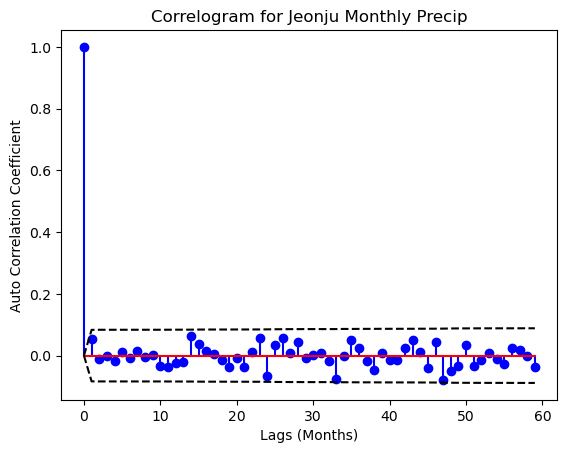

In [10]:
#---------- Remove linear trend ------------
# precip  =  detrend(precip, type='linear')  # linear detrending

#----- Calculate autocorrelation and confidence intervals ---
acf_total, conf  =  acf(precip, alpha=0.05, nlags=len(precip))
print(acf_total[0:4])            # lag 0, 1, 2, 3 의 자기상관계수

conf -= conf.mean(axis=1)[:,None]  # 0 을 중심으로 한 신뢰구간 (Practice 1 과 같음)

# ------------- Plot Correlogram --------------
plt.stem(np.arange(0,60,1), acf_total[0:60], linefmt='b-', markerfmt='bo', basefmt='r-')
plt.plot(np.arange(0,60,1), conf[0:60], 'k--')   # 점선 : Practice 1 과 같음
plt.title('Correlogram for Jeonju Monthly Precip')
plt.xlabel('Lags (Months)')
plt.ylabel('Auto Correlation Coefficient')
plt.show()

